# KAN-PIN

In [1]:
%load_ext autoreload
%autoreload 2

import os
import random
from itertools import cycle
from pathlib import Path
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from tqdm.auto import tqdm
from efficient_kan.kan import KAN
from torch.utils.data import TensorDataset, DataLoader, Sampler

import torch.optim as optim
from utils.architecture import Architecture
from rt_python.ray_tracing import DataGenerator
from utils.metrics import score

SEED = 42

c:\Users\Conciso TI\.conda\envs\exai\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using '{DEVICE}' device.")

Using 'cpu' device.


## Obtenção do conjunto de dados

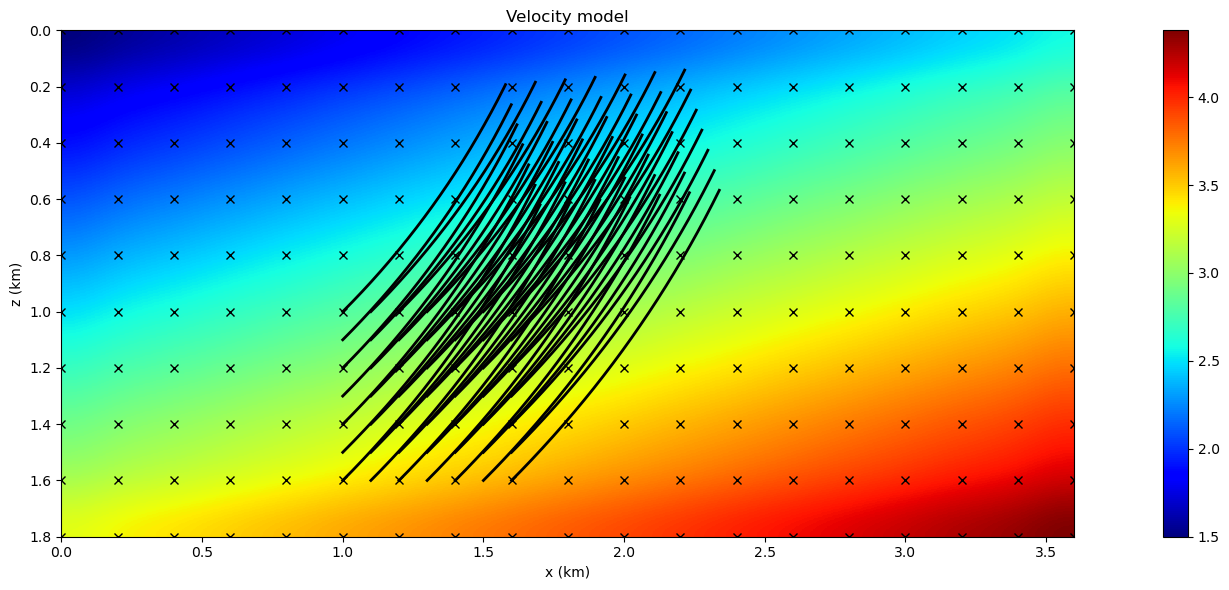

In [3]:
data_gen = DataGenerator()
# df = data_gen.run_multiple(x0_range=(0.5, 2),
#                            z0_range=(1, 1.5),
#                            theta_range=(45, 75),
#                            dx_dy=0.1,
#                            constant_speed=False)
df = data_gen.run_multiple(x0_range=(1, 1.5),
                           z0_range=(1, 1.5),
                           theta_range=(45, 45),
                           dx_dy=0.1,
                           constant_speed=False)
fig = data_gen.plot(df)
plt.show()

In [4]:
features = ['x0', 'z0', 'theta0_p', 't']
target = ['x', 'z', 'px', 'pz']

### Separando o Conjunto em Treinamento, Validação e Teste

In [5]:
initial_conditions = df[['x0', 'z0', 'theta0_p']].drop_duplicates()
aux = initial_conditions.copy()

ic_train = aux.sample(frac=0.6, random_state=SEED)
ic_val = aux.drop(ic_train.index).sample(frac=0.5, random_state=SEED)
ic_test = aux.drop(list(ic_train.index) + list(ic_val.index))

print("Train Initial Conditions:", len(ic_train))
print("Validation Initial Conditions:", len(ic_val))
print("Test Initial Conditions:", len(ic_test))

Train Initial Conditions: 29
Validation Initial Conditions: 10
Test Initial Conditions: 10


São utilizados 401 pontos para a composição do raio de 0 a 400 ms, com dt de 1 ms.

In [6]:
df_train = df.merge(ic_train, on=['x0', 'z0', 'theta0_p'], how='inner')
df_val = df.merge(ic_val, on=['x0', 'z0', 'theta0_p'], how='inner')
df_test = df.merge(ic_test, on=['x0', 'z0', 'theta0_p'], how='inner')

print("Train Size:", len(df_train))
print("Validation Size:", len(df_val))
print("Test Size:", len(df_test))

Train Size: 11629
Validation Size: 4010
Test Size: 4010


### Criação dos DataLoaders

In [7]:
class BalancedBatchSampler(Sampler):
    def __init__(self, dataset, batch_size, t_index=3, shuffle=True):
        """
    A sampler that generates balanced batches from a dataset, ensuring that each batch contains
    an equal number of samples with a specific target value.
    Args:
        dataset (Dataset): The dataset to sample from.
        batch_size (int): The number of samples per batch.
        t_index (int, optional): The index of the target value in the dataset samples. Default is 4.
        shuffle (bool, optional): Whether to shuffle the batch indices. Default is True.
        
    Attributes:
        dataset (Dataset): The dataset to sample from.
        batch_size (int): The number of samples per batch.
        t_index (int): The index of the target value in the dataset samples.
        shuffle (bool): Whether to shuffle the batch indices.
        t_zero_indices (list): Indices of samples with target value equal to 0.
        non_t_zero_indices (list): Indices of samples with target value not equal to 0.
        
    Methods:
        __iter__(): Generates balanced batches of indices.
        __len__(): Returns the number of batches.
    """
        if batch_size % 2 != 0 or batch_size <= 0:
            raise ValueError("batch_size deve ser um número inteiro positivo e par.")
        
        self.dataset = dataset
        self.batch_size = batch_size
        self.t_index = t_index
        self.shuffle = shuffle

        # Dividir o dataset em duas partes: com t=0 e sem t=0
        self.t_zero_indices = []
        self.non_t_zero_indices = []

        for i in range(len(self.dataset)):
            data = self.dataset[i]
            try:
                t_sample = data[0][self.t_index]
            except (IndexError, TypeError):
                raise ValueError(f"O índice de tempo t_index={self.t_index} não é válido.")
            if t_sample == 0:
                self.t_zero_indices.append(i)
            else:
                self.non_t_zero_indices.append(i)

        if not self.t_zero_indices or not self.non_t_zero_indices:
            raise ValueError("Não há amostras suficientes em cada classe para criar batches balanceados.")

    def __iter__(self):
        if self.shuffle:
            random.shuffle(self.t_zero_indices)
            random.shuffle(self.non_t_zero_indices)

        t_zero_iter = cycle(self.t_zero_indices)
        non_t_zero_iter = cycle(self.non_t_zero_indices)

        num_batches = len(self.dataset) // self.batch_size

        for _ in range(num_batches):
            t_zero_batch = [next(t_zero_iter) for _ in range(2)] # Samples with t=0 per batch
            non_t_zero_batch = [next(non_t_zero_iter) for _ in range(self.batch_size-2)]
            batch_indices = t_zero_batch + non_t_zero_batch

            if self.shuffle:
                random.shuffle(batch_indices)

            yield batch_indices

    def __len__(self):
        return len(self.dataset) // self.batch_size


In [8]:
# Convertendo os dados para tensores
X_train = torch.as_tensor(df_train[features].values, dtype=torch.float32)
y_train = torch.as_tensor(df_train[target].values, dtype=torch.float32)

X_val = torch.as_tensor(df_val[features].values, dtype=torch.float32)
y_val = torch.as_tensor(df_val[target].values, dtype=torch.float32)

X_test = torch.as_tensor(df_test[features].values, dtype=torch.float32)
y_test = torch.as_tensor(df_test[target].values, dtype=torch.float32)

# Criando o Dataset
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

# Criando um loader para cada conjunto de dados
sampler = BalancedBatchSampler(train_dataset, batch_size=256)
train_loader = DataLoader(dataset=train_dataset,
                          batch_sampler=sampler,
                        #   shuffle=False,
                        #   batch_size=256,
                          )

val_loader = DataLoader(dataset=val_dataset,
                        shuffle=False,
                        batch_size=256
                        )

test_loader = DataLoader(dataset=test_dataset,
                        shuffle=False,
                        batch_size=len(test_dataset)
                        )

## KAN com PINN

In [9]:
# Função de perda física ajustada
def physics_loss_fn(model, input_tensor, *args, **kwargs):
    # Separe as entradas e garanta que as variáveis requerem gradiente
    x0 = input_tensor[:, 0].view(-1, 1)  # x0
    z0 = input_tensor[:, 1].view(-1, 1)  # z0
    theta0 = input_tensor[:, 2].view(-1, 1)  # theta0
    t_var = input_tensor[:, 3].view(-1, 1)  # t

    # Certifique-se de que todas as variáveis tenham requires_grad=True para calcular derivadas
    t_var.requires_grad_(True)

    # Recalcule yhat usando as variáveis para garantir a conexão
    x_reconstructed = torch.cat([x0, z0, theta0, t_var], dim=1)
    yhat = model(x_reconstructed)
    
    x_out = yhat[:, 0].view(-1, 1)
    z_out = yhat[:, 1].view(-1, 1)
    px_out = yhat[:, 2].view(-1, 1)
    pz_out = yhat[:, 3].view(-1, 1)

    # Calcule v(x, z)
    v = 1.5 + 0.3 * x_out + z_out
    
    # If t exists in the input tensor
    t_zero_mask = (t_var == 0).squeeze()
    if t_zero_mask.any():
        x0_t0 = x0[t_zero_mask]
        z0_t0 = z0[t_zero_mask]
        
        # Ensure that in t = 0, x = x0 and z = z0
        x_initial_condition = (yhat[t_zero_mask, 0] - x0_t0) ** 2
        z_initial_condition = (yhat[t_zero_mask, 1] - z0_t0) ** 2
        initial_condition_loss = torch.mean(x_initial_condition + z_initial_condition)
    else:
        # If t=0 is not present, loss = 0
        initial_condition_loss = 0
    

    # Calcule os gradientes necessários
    dxdt = torch.autograd.grad(
        outputs=x_out,  # Derivada de x em relação a t
        inputs=t_var,
        grad_outputs=torch.ones_like(x_out),
        create_graph=True,
        retain_graph=True
    )[0]

    dzdt = torch.autograd.grad(
        outputs=z_out,  # Derivada de z em relação a t
        inputs=t_var,
        grad_outputs=torch.ones_like(z_out),
        create_graph=True,
        retain_graph=True
    )[0]

    dpxdt = torch.autograd.grad(
        outputs=px_out,  # Derivada de px em relação a t
        inputs=t_var,
        grad_outputs=torch.ones_like(px_out),
        create_graph=True,
        retain_graph=True
    )[0]

    dpzdt = torch.autograd.grad(
        outputs=pz_out,  # Derivada de pz em relação a t
        inputs=t_var,
        grad_outputs=torch.ones_like(pz_out),
        create_graph=True,
        retain_graph=True
    )[0]

    # Equações diferenciais conforme sua figura
    pde1 = dxdt - v ** 2 * px_out
    pde2 = dzdt - v ** 2 * pz_out
    pde3 = dpxdt + (torch.autograd.grad(torch.log(v), x_out,
                    torch.ones_like(v), create_graph=True)[0])
    pde4 = dpzdt + (torch.autograd.grad(torch.log(v), z_out,
                    torch.ones_like(v), create_graph=True)[0])

    # Calcular a perda como a soma dos erros quadrados das PDEs
    loss = torch.mean(pde1 ** 2 + pde2 ** 2 + pde3 ** 2 + pde4 ** 2 + 2 * initial_condition_loss)

    return loss

## Treinamento do Modelo

In [10]:
def sin():
    return torch.sin

In [11]:
torch.manual_seed(42)
input_size = len(features)
output_size = len(target)
model = KAN([input_size, 12, 11, 10, 9, 8, 7, 6, output_size], grid_size=12,
            spline_order=3, base_activation=sin)

# Defines optimizer to update the parameters
optimizer = optim.Adam(model.parameters(),
                        lr=1e-3)


# Defines a MSE loss function
loss_fn = torch.nn.MSELoss(reduction='mean')

In [12]:
arch = Architecture(model, loss_fn, physics_loss_fn,
                    optimizer, lamb=1e-3, lamb_l1=1e-3,
                    lamb_entropy=2, lambda_physics=1e-3)
arch.set_loaders(train_loader, val_loader)

Último treinamento: Loss = 0.155

In [13]:
n_epochs = 10
arch.train(n_epochs=n_epochs, seed=SEED)

Training PIKAN: 100%|██████████| 10/10 [01:09<00:00,  6.99s/it, data_loss=0.0108, loss=0.0536, physics_loss=0.000416, val_loss=0.0134]


In [21]:
arch.save_checkpoint("output/checkpoint_100epochs.pt")

C:\Users\Conciso TI\AppData\Local\Temp\ipykernel_7252\4065197815.py:2: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


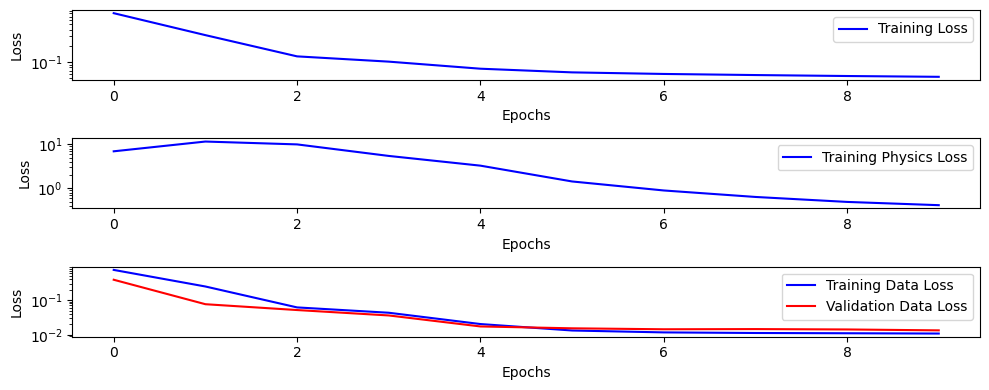

In [14]:
fig = arch.plot_losses()
fig.show()

In [23]:
# arch.load_checkpoint("output/pikan_best.pt")

In [24]:
predictions = arch.predict(df_test[features].values)
df_pred = pd.DataFrame(predictions, columns=target)
df_pred = df_test[features].join(df_pred)
df_pred.head()

,x0,z0,theta0_p,t,x,z,px,pz
0,1.0,1.0,2.268928,0.000,1.052468,1.011359,0.271118,-0.216223
1,1.0,1.0,2.268928,0.001,1.053771,1.009793,0.271178,-0.216495
2,1.0,1.0,2.268928,0.002,1.055078,1.008229,0.271235,-0.216768
3,1.0,1.0,2.268928,0.003,1.056388,1.006665,0.271291,-0.217043
4,1.0,1.0,2.268928,0.004,1.057702,1.005102,0.271345,-0.217319


In [25]:
score(df_pred[target].values, df_test[target].values)

,X,Z,Px,Pz
R²,0.984259,0.982222,0.941037,0.939035
MAPE,0.018375,0.038500,0.022373,0.070469
MAE,0.034674,0.034724,0.005682,0.012739
MSE,0.002041,0.001624,0.000057,0.000247
RMSE,0.045172,0.040302,0.007526,0.015722


/tmp/ipykernel_947/3008537375.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])


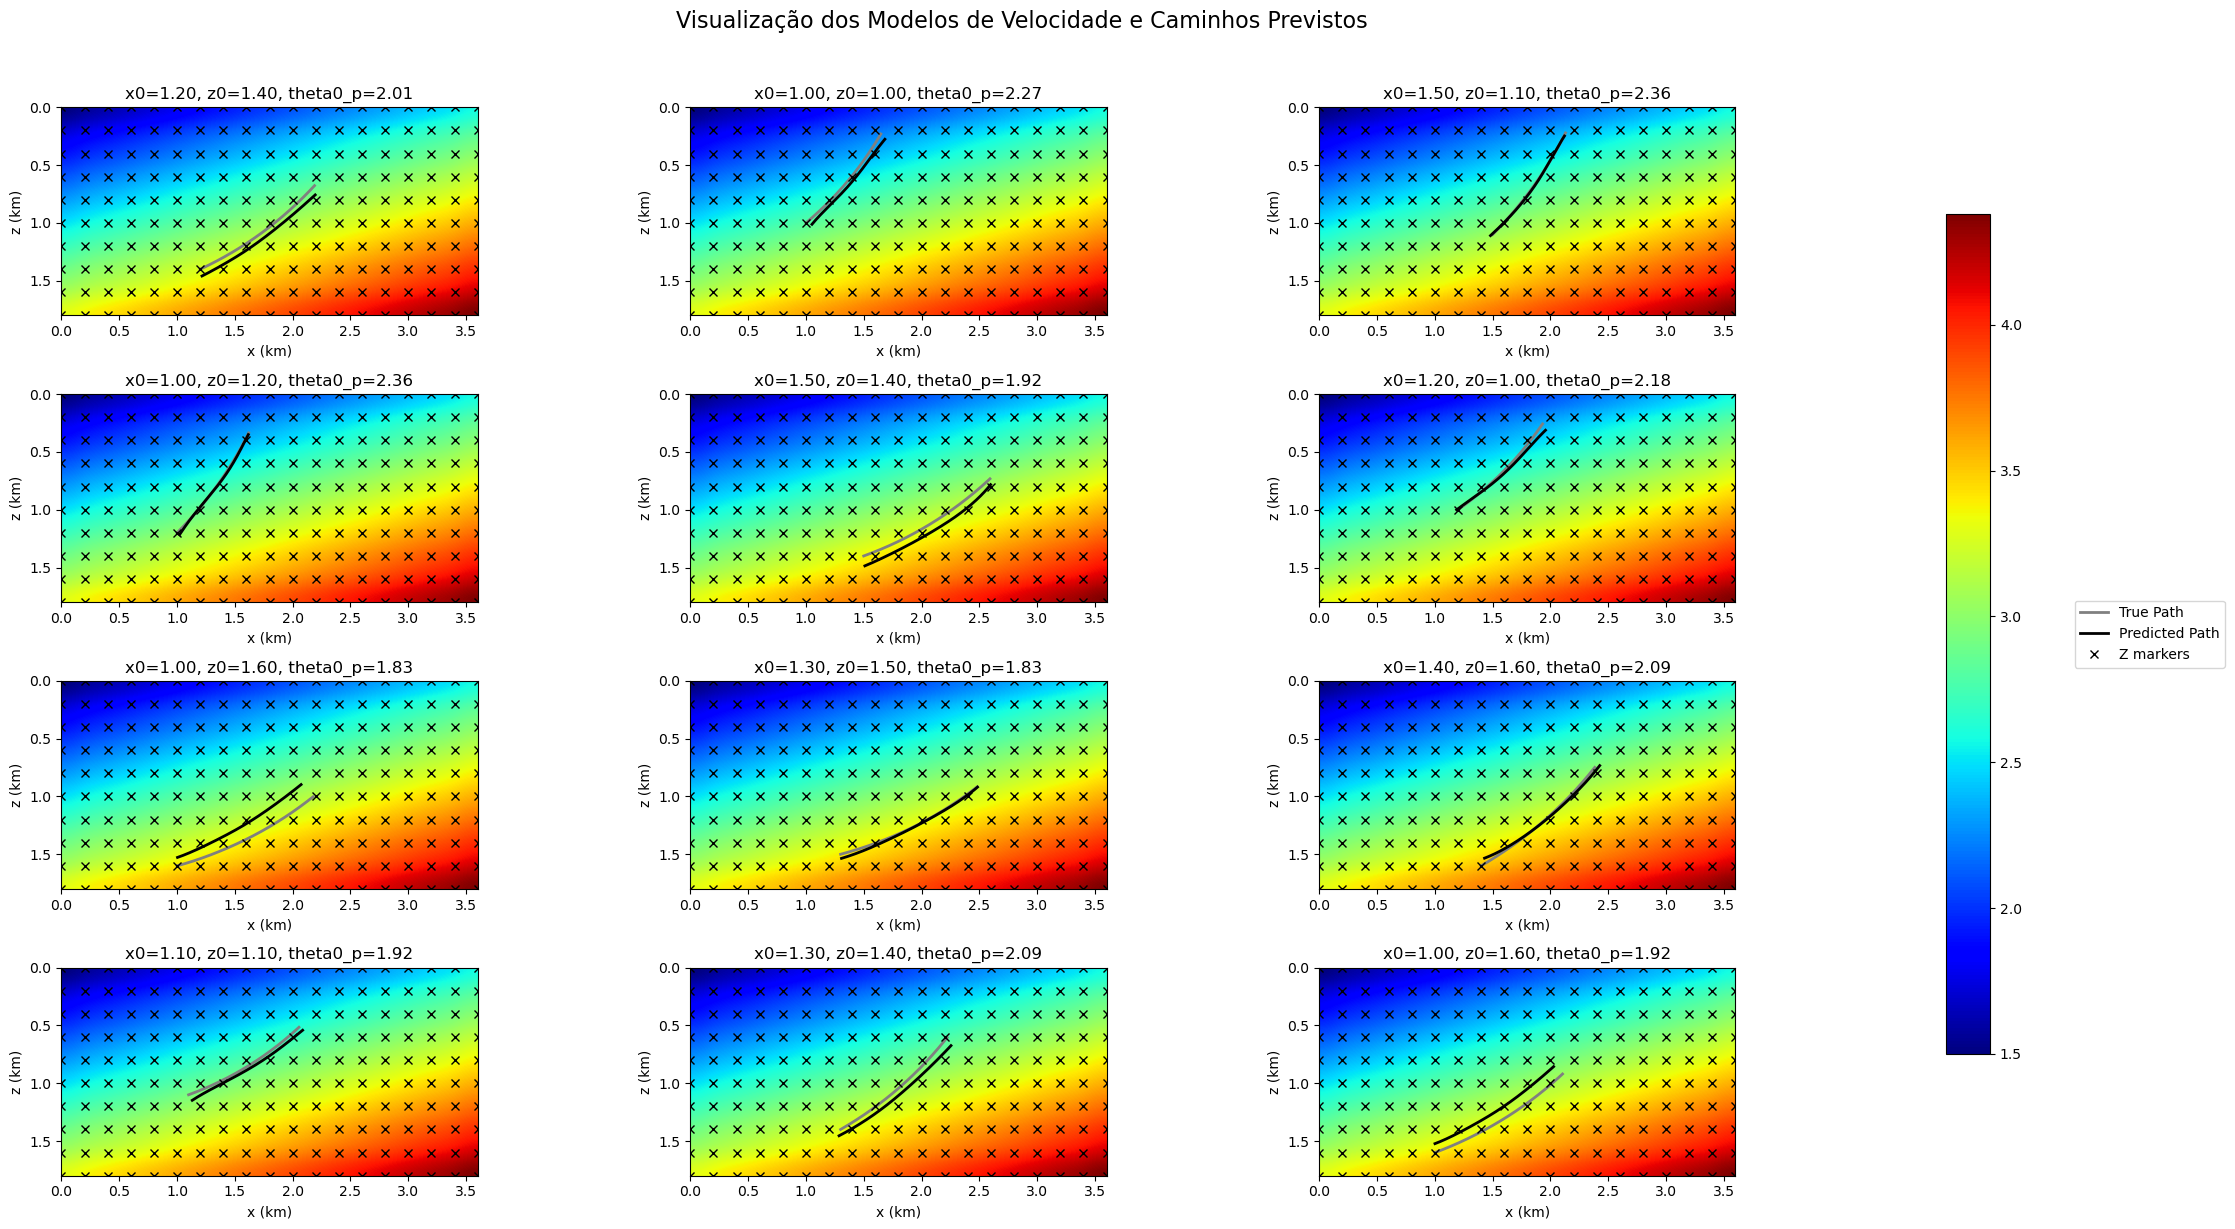

In [ ]:
# Número de subplots desejados
unique_initial_conditions = (df_test[features]
                             .drop(columns=['t'])
                             .drop_duplicates()
                             .sample(12, random_state=SEED)
                             )
n_initial_conditions = unique_initial_conditions.shape[0]
cols = 3
rows = (n_initial_conditions + cols - 1) // cols
fig, axs = plt.subplots(rows, cols, figsize=(22, 12))
axs = axs.flatten()  # Achatar para iterar facilmente

# Encontrar os valores mínimos e máximos de data_gen.Vbsplines para definir a barra de cores dinamicamente
vmin, vmax = np.min(data_gen.Vbsplines), np.max(data_gen.Vbsplines)

# Matrizes para armazenar raios individualmente


for ax, (x0, z0, theta0_p) in zip(axs[:n_initial_conditions], unique_initial_conditions.values):
    initial_condition = (
        (df_test['x0'] == x0) &
        (df_test['z0'] == z0) &
        (df_test['theta0_p'] == theta0_p)
    )

    im = ax.imshow(np.flipud(data_gen.Vbsplines), extent=[data_gen.x_range[0],
                                                          data_gen.x_range[1],
                                                          data_gen.z_range[0],
                                                          data_gen.z_range[-1]],
                   vmin=vmin, vmax=vmax)
    ax.set_title(f'{x0=:.2f}, {z0=:.2f}, {theta0_p=:.2f}')
    ax.plot(df_test.loc[initial_condition, 'x'],
            df_test.loc[initial_condition, 'z'],
            color='grey',
            linewidth=2,
            label='True Path'
            )
    ax.plot(df_pred.loc[initial_condition, 'x'],
            df_pred.loc[initial_condition, 'z'],
            color='black',
            linewidth=2,
            label='Predicted Path'
            )
    for zi in data_gen.z:
        ax.plot(data_gen.x, zi *
                np.ones_like(data_gen.x), 'kx', linewidth=2)

    ax.set_xlabel('x (km)')
    ax.set_ylabel('z (km)')
    ax.invert_yaxis()
    
    

# Adicionar uma barra de cores geral para a figura inteira
# Definir a posição da barra de cores
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
fig.colorbar(im, cax=cbar_ax)

# Adicionar uma única legenda fora da área dos subplots
legend_elements = [
    Line2D([0], [0], color='grey', lw=2, label='True Path'),
    Line2D([0], [0], color='black', lw=2, label='Predicted Path'),
    Line2D([0], [0], color='k', marker='x', lw=0, label='Z markers')
]
fig.legend(handles=legend_elements, loc='center right', bbox_to_anchor=(1.05, 0.5))

fig.suptitle('Visualização dos Modelos de Velocidade e Caminhos Previstos', fontsize=16, y=1.02)

for ax in axs[n_initial_conditions:]:
    ax.axis('off')  # Desativar eixos para subplots vazios

# Ajustar layout para evitar sobreposição
plt.tight_layout(rect=[0, 0, 0.9, 1])
plt.subplots_adjust(right=0.88)  # Ajustar espaço para a legenda
plt.show()


## Teste 2

In [ ]:
# Inicializar matrizes para armazenar os raios de teste e preditos
test_rays = []
predicted_rays = []

# Usar todas as condições iniciais únicas no conjunto de teste
unique_initial_conditions = df_test[['x0', 'z0', 'theta0_p']].drop_duplicates()

# Iterar pelas condições iniciais do conjunto de teste
for x0, z0, theta0_p in unique_initial_conditions.values:
    initial_condition = (
        (df_test['x0'] == x0) &
        (df_test['z0'] == z0) &
        (df_test['theta0_p'] == theta0_p)
    )
    
    # Extrair os raios correspondentes e armazenar em array
    test_ray = df_test.loc[initial_condition, ['x', 'z']].values
    predicted_ray = df_pred.loc[initial_condition, ['x', 'z']].values
    
    test_rays.append(test_ray)
    predicted_rays.append(predicted_ray)

# Converter as listas em arrays numpy para fácil manipulação
test_rays_matrix = np.array(test_rays)
predicted_rays_matrix = np.array(predicted_rays)

# Verificar dimensões das matrizes
print("Dimensões da matriz de raios de teste:", test_rays_matrix.shape)
print("Dimensões da matriz de raios preditos:", predicted_rays_matrix.shape)

Dimensões da matriz de raios de teste: (69, 401, 2)
Dimensões da matriz de raios preditos: (69, 401, 2)


In [52]:
predicted_rays_matrix

array([[[1.052468  , 1.011359  ],
        [1.0537711 , 1.0097933 ],
        [1.0550779 , 1.0082285 ],
        ...,
        [1.6800239 , 0.27949405],
        [1.6814934 , 0.2777297 ],
        [1.6829627 , 0.27597207]],

       [[1.0674634 , 1.0432032 ],
        [1.0689273 , 1.0419333 ],
        [1.0703969 , 1.0406644 ],
        ...,
        [1.9126639 , 0.4179018 ],
        [1.9146478 , 0.41616446],
        [1.9166299 , 0.4144321 ]],

       [[1.0355046 , 1.1181421 ],
        [1.0369848 , 1.1163306 ],
        [1.0384696 , 1.1145194 ],
        ...,
        [1.6975632 , 0.3487489 ],
        [1.698927  , 0.34678832],
        [1.700288  , 0.34483328]],

       ...,

       [[1.5089478 , 1.5356209 ],
        [1.512065  , 1.5344236 ],
        [1.5151811 , 1.5332174 ],
        ...,
        [2.5042183 , 0.734448  ],
        [2.5057445 , 0.73224145],
        [2.507266  , 0.73003745]],

       [[1.5074661 , 1.5498917 ],
        [1.5107358 , 1.5488808 ],
        [1.5140073 , 1.5478618 ],
        .

In [ ]:
# Calcular a diferença absoluta ponto a ponto (raios preditos - raios reais)
diferenca = np.abs(predicted_rays_matrix - test_rays_matrix)  # Diferença absoluta

# Calcular o erro médio por raio
# Média sobre pontos (401) e coordenadas (x, z)
erro_medio_raio = np.mean(diferenca, axis=(1, 2))

# Obter as origens (x0, z0, theta0_p) diretamente do DataFrame 'unique_initial_conditions'
# Cada origem é uma tupla (x0, z0, theta0_p)
origens = unique_initial_conditions.values  # já tem as 69 condições iniciais do conjunto de teste

# Criar um DataFrame para armazenar as informações, com 4 casa decimais
dados = {
    'Raio (x0, z0, θ)': [f"({origens[i][0]:.4f}, {origens[i][1]:.4f}, {origens[i][2]:.4f})" for i in range(len(origens))],
    'Diferença Média': erro_medio_raio
}

tabela_diferencas = pd.DataFrame(dados)

# Exibir a tabela
print(tabela_diferencas)


            Raio (x0, z0, θ)  Diferença Média
0   (1.0000, 1.0000, 2.2689)         0.028723
1   (1.0000, 1.0000, 2.0071)         0.035194
2   (1.0000, 1.1000, 2.2689)         0.026252
3   (1.0000, 1.1000, 1.8326)         0.015187
4   (1.0000, 1.2000, 2.3562)         0.010255
..                       ...              ...
64  (1.6000, 1.5000, 2.3562)         0.057632
65  (1.6000, 1.5000, 1.9199)         0.058581
66  (1.6000, 1.6000, 2.0944)         0.051381
67  (1.6000, 1.6000, 1.9199)         0.064155
68  (1.6000, 1.6000, 1.8326)         0.079508

[69 rows x 2 columns]


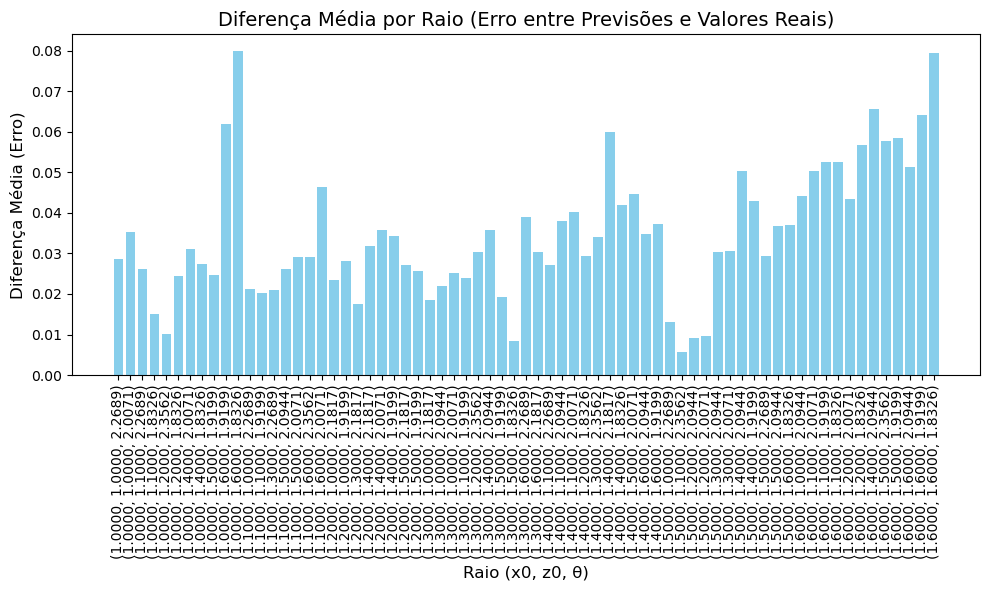

In [60]:
# Plotando a diferença média por raio
plt.figure(figsize=(10, 6))

# Gráfico de barras para a diferença média de erro
plt.bar(tabela_diferencas['Raio (x0, z0, θ)'], tabela_diferencas['Diferença Média'], color='skyblue')

# Adicionando título e rótulos aos eixos
plt.title('Diferença Média por Raio (Erro entre Previsões e Valores Reais)', fontsize=14)
plt.xlabel('Raio (x0, z0, θ)', fontsize=12)
plt.ylabel('Diferença Média (Erro)', fontsize=12)

# Rotacionar os rótulos no eixo x para melhor visualização
plt.xticks(rotation=90, fontsize=10)

# Ajuste para não sobrepor rótulos
plt.tight_layout()

# Exibir o gráfico
plt.show()


In [70]:
# import matplotlib.pyplot as plt
# import math

# # Número de raios a serem visualizados
# num_raios = test_rays_matrix.shape[0]

# # Calcular o número de linhas e colunas com base no número de raios
# num_cols = 4
# num_rows = math.ceil(num_raios / num_cols)  # Arredondar para cima para garantir espaço suficiente

# # Criar subplots dinamicamente com base no número de raios
# fig, axes = plt.subplots(num_rows, num_cols, figsize=(40, 60))
# axes = axes.flatten()

# # Iterar sobre cada raio para plotar as diferenças
# for i in range(num_raios):
#     raio_real = test_rays_matrix[i]  # Raio real (test)
#     raio_predito = predicted_rays_matrix[i]  # Raio predito
#     dif_raio = diferenca[i]  # Diferença ponto a ponto (401, 2)
    
#     # Plotar as diferenças de x e z
#     axes[i].plot(dif_raio[:, 0], label='Diferença em x', color='red', )
#     axes[i].plot(dif_raio[:, 1], label='Diferença em z', color='blue')
    
#     # Título, rótulos e legenda
#     axes[i].set_title(f'Raio {i+1} (Erro Médio: {erro_medio_raio[i]:.4f})')
#     axes[i].set_xlabel('Ponto no tempo')
#     axes[i].set_ylabel('Diferença')
#     axes[i].grid()
#     axes[i].legend(fontsize=8)

# # Ajustar layout
# plt.tight_layout()
# plt.show()

# # Resumo do erro médio para cada raio
# for i, erro in enumerate(erro_medio_raio, start=1):
#     print(f'Raio {i}: Erro Médio = {erro:.4f}')


tornar o código aplicável para qualquer modelo  

- Urgência:  
plotar em diagrama de cor  
scatterplot 3d  
pairplot
